# Fase 2 · Hipótesis y pruebas estadísticas
**Evento Evaluativo 3 · Análisis de Datos (ITM, 2026-2) · Grupo 2 · Clientes bancarios**

En la Fase 1 vimos pistas: Alemania parece perder más clientes, los inactivos se van más, los que se fueron son mayores. Pero una diferencia en una muestra puede ser casualidad. Aquí pasamos **de la observación a la validación**: planteamos hipótesis y las probamos con estadística para decidir con evidencia.

Los 10.000 clientes son una **muestra**. Las hipótesis hablan de la **población**: los clientes del banco en general. Lo que queremos saber es si lo que vemos en la muestra también pasa allá afuera.

## 1. Reglas del juego
Fijamos las reglas antes de mirar ningún resultado, para no ajustarlas después a lo que nos convenga.

| Regla | Qué usamos |
|---|---|
| Nivel de significancia (α) | 0,05. Aceptamos un 5 % de riesgo de equivocarnos al rechazar H0 |
| Decisión | Si p < α se **rechaza H0**. Si p ≥ α **no se rechaza H0** (nunca decimos "se acepta") |
| Tipo de prueba | **Bilateral** en todas: no suponemos de antemano en qué dirección va la diferencia |
| Tamaño del efecto | Siempre lo reportamos. Con 10.000 filas casi todo sale "significativo", así que p solo no basta |
| Intervalos de confianza | 95 % para las tasas y para las diferencias de medias |

**Qué significan los errores en este caso:**

| Error | Qué pasaría en el banco |
|---|---|
| Tipo I (rechazar H0 cuando era cierta) | Creer que un grupo se va más cuando no es así, y gastar dinero en retener a quien no lo necesita |
| Tipo II (no rechazar H0 cuando era falsa) | No ver un grupo que sí está en riesgo y seguir perdiendo clientes sin actuar |

## 2. Preparación
Cargamos los datos y dejamos listas unas funciones para repetir los cálculos en cada hipótesis.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

def ruta_dataset():
    # Busca primero el archivo en la caché de kagglehub (rápido). Si no está, lo descarga.
    base = os.path.expanduser("~/.cache/kagglehub/datasets/shubh0799/churn-modelling/versions")
    if os.path.isdir(base):
        for version in sorted(os.listdir(base), reverse=True):
            carpeta = os.path.join(base, version)
            if os.path.exists(os.path.join(carpeta, "Churn_Modelling.csv")):
                return carpeta
    import kagglehub
    return kagglehub.dataset_download("shubh0799/churn-modelling")


df = pd.read_csv(os.path.join(ruta_dataset(), "Churn_Modelling.csv"))
print(df.shape)

ALFA = 0.05
resultados = []   # aquí guardamos el resumen de cada hipótesis

(10000, 14)


In [2]:
def fmt_p(p):
    # Cuando p es tan pequeño que el computador lo redondea a 0, lo decimos claro
    return "menor que 1e-300 (el computador lo redondea a 0)" if p == 0 else f"{p:.3e}"


def decision(p, alfa=ALFA):
    return "Se rechaza H0" if p < alfa else "No se rechaza H0"


def wilson(k, n, z=1.96):
    # Intervalo de confianza del 95 % para una proporción
    p = k / n
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centro - margen, centro + margen


def tasa_con_ic(columna):
    # Tasa de abandono por categoría, con su intervalo de confianza
    filas = []
    for categoria, g in df.groupby(columna):
        n, k = len(g), int(g["Exited"].sum())
        bajo, alto = wilson(k, n)
        filas.append({"categoria": categoria, "clientes": n, "se_fueron": k,
                      "abandono_%": round(k / n * 100, 1),
                      "IC95_bajo_%": round(bajo * 100, 1), "IC95_alto_%": round(alto * 100, 1)})
    return pd.DataFrame(filas).set_index("categoria")


def grafico_tasas(tabla, titulo, etiqueta_x):
    fig, ax = plt.subplots(figsize=(6, 4))
    x = np.arange(len(tabla))
    err = [tabla["abandono_%"] - tabla["IC95_bajo_%"], tabla["IC95_alto_%"] - tabla["abandono_%"]]
    ax.bar(x, tabla["abandono_%"], yerr=err, capsize=5)
    ax.set_xticks(x)
    ax.set_xticklabels(tabla.index.astype(str))
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel("% que se fue")
    ax.set_title(titulo)
    plt.show()


def chi_cuadrado(tabla):
    chi2, p, gl, esperados = stats.chi2_contingency(tabla)
    n = tabla.values.sum()
    k = min(tabla.shape) - 1
    v = np.sqrt(chi2 / (n * k))           # V de Cramér
    esperados = pd.DataFrame(esperados, index=tabla.index, columns=tabla.columns)
    residuos = (tabla - esperados) / np.sqrt(esperados)
    return chi2, p, gl, esperados, v, k, residuos


def tamano_v(v, k):
    # Referencias de Cohen ajustadas por los grados de libertad de la tabla
    if v < 0.1 / np.sqrt(k): return "muy pequeño"
    if v < 0.3 / np.sqrt(k): return "pequeño"
    if v < 0.5 / np.sqrt(k): return "mediano"
    return "grande"


def welch(g1, g0):
    # Prueba t que no supone varianzas iguales (Welch), con diferencia, IC y d de Cohen
    t, p = stats.ttest_ind(g1, g0, equal_var=False)
    diff = g1.mean() - g0.mean()
    v1, v0 = g1.var(ddof=1) / len(g1), g0.var(ddof=1) / len(g0)
    gl = (v1 + v0) ** 2 / (v1**2 / (len(g1) - 1) + v0**2 / (len(g0) - 1))
    ic = diff + np.array([-1, 1]) * stats.t.ppf(0.975, gl) * np.sqrt(v1 + v0)
    sp = np.sqrt(((len(g1) - 1) * g1.var(ddof=1) + (len(g0) - 1) * g0.var(ddof=1)) / (len(g1) + len(g0) - 2))
    return t, p, gl, diff, ic, diff / sp


def tamano_d(d):
    d = abs(d)
    if d < 0.2: return "muy pequeño"
    if d < 0.5: return "pequeño"
    if d < 0.8: return "mediano"
    return "grande"

## 3. Hipótesis 1 · Edad y abandono

### 3.1 Lo que observamos
Antes de plantear la hipótesis, miramos cómo se ve la edad en los dos grupos.

        count  mean  median   std
Exited                           
0        7963  37.4    36.0  10.1
1        2037  44.8    45.0   9.8


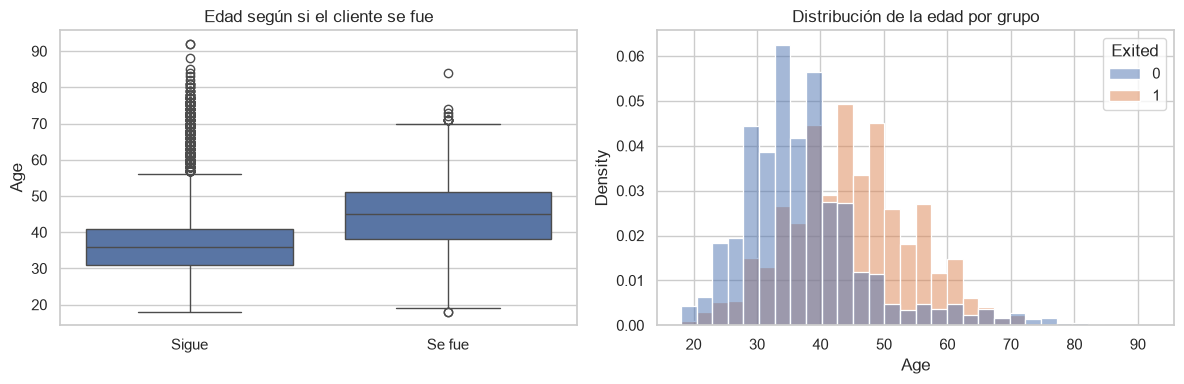

In [3]:
se_fueron = df.loc[df["Exited"] == 1, "Age"]
siguen = df.loc[df["Exited"] == 0, "Age"]

print(df.groupby("Exited")["Age"].agg(["count", "mean", "median", "std"]).round(1))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Exited", y="Age", ax=ejes[0])
ejes[0].set_xticks([0, 1]); ejes[0].set_xticklabels(["Sigue", "Se fue"])
ejes[0].set_title("Edad según si el cliente se fue"); ejes[0].set_xlabel("")
sns.histplot(data=df, x="Age", hue="Exited", stat="density", common_norm=False, bins=30, ax=ejes[1])
ejes[1].set_title("Distribución de la edad por grupo")
plt.tight_layout(); plt.show()

Los que se fueron tienen más edad: promedio de 44,8 años y mediana de 45, contra 37,4 y 36 de los que se quedaron. En el boxplot, la caja de los que se fueron queda más arriba. Falta saber si esa diferencia es real o casualidad.

### 3.2 Hipótesis
- **H0:** la edad promedio de los clientes que se van es **igual** a la de los que se quedan (μ_se_fue = μ_sigue).
- **H1:** la edad promedio es **distinta** (μ_se_fue ≠ μ_sigue).

**Por qué importa al negocio:** si la edad separa a los que se van, el banco puede dirigir campañas de retención a ciertos rangos de edad.

**Por qué esta prueba:** comparamos el **promedio de una variable numérica entre dos grupos**, que es el caso de la **t de Student**. Usamos la versión de **Welch**, que no necesita que los dos grupos tengan la misma varianza.

### 3.3 Revisar los supuestos
La t de Student pide que los datos sean razonablemente normales o que las muestras sean grandes. Lo revisamos en vez de darlo por hecho.

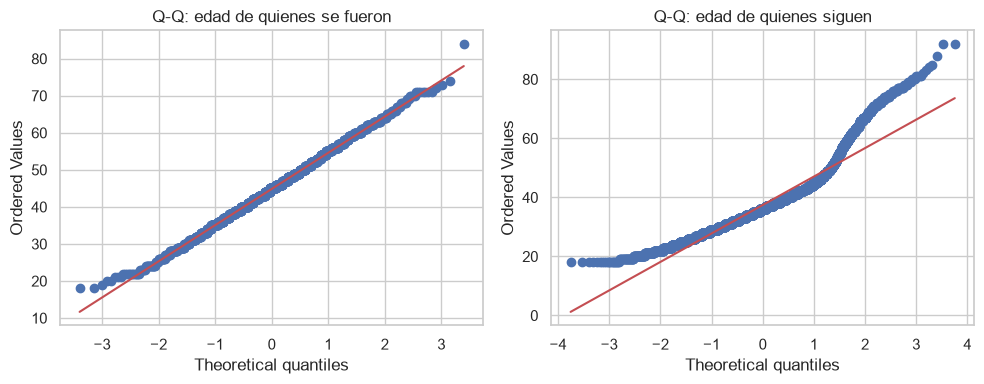

Asimetría (0 = simétrica):  se fueron = 0.08 | siguen = 1.38
Tamaño de cada grupo:        se fueron = 2037 | siguen = 7963
Prueba de Levene (¿varianzas iguales?): p = 0.0003


In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(se_fueron, dist="norm", plot=ejes[0]); ejes[0].set_title("Q-Q: edad de quienes se fueron")
stats.probplot(siguen, dist="norm", plot=ejes[1]);    ejes[1].set_title("Q-Q: edad de quienes siguen")
plt.tight_layout(); plt.show()

print("Asimetría (0 = simétrica):  se fueron =", round(se_fueron.skew(), 2), "| siguen =", round(siguen.skew(), 2))
print("Tamaño de cada grupo:        se fueron =", len(se_fueron), "| siguen =", len(siguen))

lev, p_lev = stats.levene(se_fueron, siguen)
print("Prueba de Levene (¿varianzas iguales?): p =", round(p_lev, 4))

**Cómo leerlo:**
- Si los puntos del Q-Q siguen la línea, hay normalidad. El grupo que se fue es casi simétrico (asimetría 0,08) y sigue bien la línea. El grupo que se quedó tiene una cola hacia las edades altas (asimetría 1,38), por eso se separa de la línea arriba a la derecha.
- Levene da p = 0,0003, así que técnicamente las varianzas no son iguales. Pero las desviaciones son casi iguales (10,1 y 9,8): con tantos datos, Levene detecta diferencias minúsculas. Por eso usamos Welch, que no las necesita iguales.
- Cada grupo tiene miles de datos, así que por el teorema del límite central el **promedio** se comporta de forma normal y la t es confiable.
- Como respaldo hacemos también **Mann-Whitney**, que no pide normalidad.

### 3.4 La prueba

In [5]:
t, p, gl, diff, ic, d = welch(se_fueron, siguen)
u, p_mw = stats.mannwhitneyu(se_fueron, siguen, alternative="two-sided")

print(f"t de Welch:  t = {t:.2f} | gl = {gl:.0f} | p = {fmt_p(p)}")
print(f"Mann-Whitney: p = {fmt_p(p_mw)}")
print(f"Diferencia de edad promedio (se fueron − siguen): {diff:.1f} años")
print(f"IC 95 % de la diferencia: [{ic[0]:.1f}, {ic[1]:.1f}] años")
print(f"d de Cohen = {d:.2f} → efecto {tamano_d(d)}")
print()
print("Decisión (α = 0,05):", decision(p))

resultados.append({"Hipótesis": "H1 Edad", "Prueba": "t de Welch", "Estadístico": round(t, 2), "p": p,
                   "Decisión": decision(p), "Tamaño del efecto": f"d = {d:.2f} ({tamano_d(d)})"})

t de Welch:  t = 30.42 | gl = 3248 | p = 4.713e-179
Mann-Whitney: p = 3.210e-230
Diferencia de edad promedio (se fueron − siguen): 7.4 años
IC 95 % de la diferencia: [7.0, 7.9] años
d de Cohen = 0.74 → efecto mediano

Decisión (α = 0,05): Se rechaza H0


### 3.5 Qué significa
- **Decisión:** p = 4,7 × 10⁻¹⁷⁹, muchísimo menor que 0,05. Se rechaza H0: la diferencia de edad no parece casualidad. Mann-Whitney llega a la misma decisión.
- **Cuánta diferencia:** los que se fueron son en promedio 7,4 años mayores. Con 95 % de confianza, esa diferencia está entre 7,0 y 7,9 años.
- **Qué tan importante:** d de Cohen = 0,74, un efecto mediano, cercano a grande. La edad separa bien a los dos grupos.
- **Para el banco:** los clientes mayores son un grupo al que conviene dirigir acciones de retención.
- **Con cuidado:** la edad y el abandono van juntos, pero no sabemos que la edad sea la causa de que se vayan.

## 4. Hipótesis 2 · País y abandono

### 4.1 Lo que observamos

           clientes  se_fueron  abandono_%  IC95_bajo_%  IC95_alto_%
categoria                                                           
France         5014        810        16.2         15.2         17.2
Germany        2509        814        32.4         30.6         34.3
Spain          2477        413        16.7         15.3         18.2


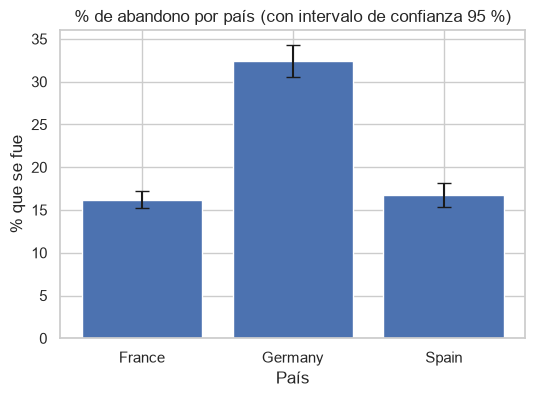

In [6]:
tabla_pais = tasa_con_ic("Geography")
print(tabla_pais)
grafico_tasas(tabla_pais, "% de abandono por país (con intervalo de confianza 95 %)", "País")

Alemania pierde el 32,4 % de sus clientes, el doble que Francia (16,2 %) y España (16,7 %). El intervalo de confianza de Alemania (30,6 a 34,3 %) no se toca con los de los otros dos países, y Francia y España casi coinciden.

### 4.2 Hipótesis
- **H0:** el abandono es **independiente** del país (la proporción de clientes que se van es la misma en los tres países).
- **H1:** el abandono **depende** del país.

**Por qué importa al negocio:** si un país pierde más clientes, la estrategia de retención debe ser distinta según el mercado.

**Por qué esta prueba:** cruzamos dos variables **categóricas** (país y abandono), que es el caso del **chi-cuadrado de independencia**.

### 4.3 Revisar el supuesto
El chi-cuadrado pide que las frecuencias **esperadas** en cada celda sean de al menos 5.

In [7]:
obs = pd.crosstab(df["Geography"], df["Exited"])
chi2, p, gl, esp, v, k, res = chi_cuadrado(obs)

print("Frecuencias observadas:");  print(obs); print()
print("Frecuencias esperadas si H0 fuera cierta:");  print(esp.round(1)); print()
print("Esperada mínima:", round(esp.values.min(), 1), "→", "cumple el supuesto" if esp.values.min() >= 5 else "NO cumple")

Frecuencias observadas:
Exited        0    1
Geography           
France     4204  810
Germany    1695  814
Spain      2064  413

Frecuencias esperadas si H0 fuera cierta:
Exited          0       1
Geography                
France     3992.6  1021.4
Germany    1997.9   511.1
Spain      1972.4   504.6

Esperada mínima: 504.6 → cumple el supuesto


### 4.4 La prueba

In [8]:
print(f"Chi-cuadrado = {chi2:.1f} | gl = {gl} | p = {fmt_p(p)}")
print(f"V de Cramér = {v:.2f} → efecto {tamano_v(v, k)}")
print()
print("Residuos estandarizados (más de ±2 = la celda se aleja de lo esperado):")
print(res.round(1))
print()
print("Decisión (α = 0,05):", decision(p))

resultados.append({"Hipótesis": "H2 País", "Prueba": "Chi-cuadrado", "Estadístico": round(chi2, 1), "p": p,
                   "Decisión": decision(p), "Tamaño del efecto": f"V = {v:.2f} ({tamano_v(v, k)})"})

Chi-cuadrado = 301.3 | gl = 2 | p = 3.830e-66
V de Cramér = 0.17 → efecto pequeño

Residuos estandarizados (más de ±2 = la celda se aleja de lo esperado):
Exited       0     1
Geography           
France     3.3  -6.6
Germany   -6.8  13.4
Spain      2.1  -4.1

Decisión (α = 0,05): Se rechaza H0


### 4.5 Qué significa
- **Decisión:** p = 3,8 × 10⁻⁶⁶, menor que 0,05. Se rechaza H0: el abandono y el país no son independientes.
- **Dónde está la diferencia:** en Alemania se fueron 814 clientes y, si el país no importara, se esperarían unos 511 (residuo +13,4). Francia y España tienen menos abandono del esperado (residuos −6,6 y −4,1).
- **Qué tan fuerte:** V de Cramér = 0,17, efecto pequeño. El país importa, pero no explica todo.
- **Para el banco:** Alemania es el mercado donde más clientes se pierden. Conviene entender qué pasa allí; la causa no está en estos datos.

## 5. Hipótesis 3 · Actividad del cliente y abandono

### 5.1 Lo que observamos

          clientes  se_fueron  abandono_%  IC95_bajo_%  IC95_alto_%
Inactivo      4849       1302        26.9         25.6         28.1
Activo        5151        735        14.3         13.3         15.3


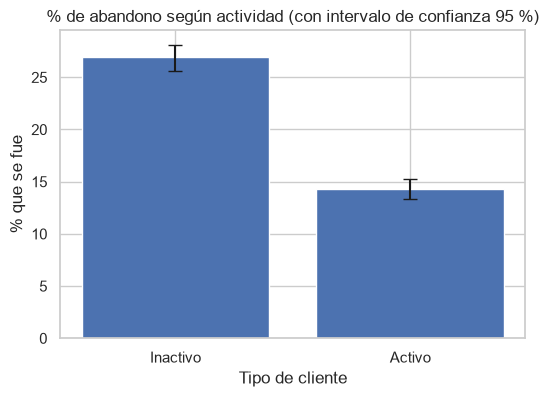

In [9]:
tabla_act = tasa_con_ic("IsActiveMember")
tabla_act.index = ["Inactivo", "Activo"]
print(tabla_act)
grafico_tasas(tabla_act, "% de abandono según actividad (con intervalo de confianza 95 %)", "Tipo de cliente")

### 5.2 Hipótesis
- **H0:** el abandono es **independiente** de que el cliente esté activo o no.
- **H1:** el abandono **depende** de la actividad del cliente.

**Por qué importa al negocio:** si la inactividad avisa que un cliente se va a ir, el banco puede reaccionar antes. Es una señal temprana y barata de seguir.

**Prueba:** chi-cuadrado de independencia (dos variables categóricas). Al ser una tabla de 2×2, scipy aplica por defecto la corrección de Yates, que es más prudente.

### 5.3 Supuesto y prueba

In [10]:
obs = pd.crosstab(df["IsActiveMember"], df["Exited"])
obs.index = ["Inactivo", "Activo"]
chi2, p, gl, esp, v, k, res = chi_cuadrado(obs)

print("Frecuencias observadas:");  print(obs); print()
print("Esperada mínima:", round(esp.values.min(), 1), "→", "cumple el supuesto" if esp.values.min() >= 5 else "NO cumple")
print()
print(f"Chi-cuadrado = {chi2:.1f} | gl = {gl} | p = {fmt_p(p)}")
print(f"V de Cramér = {v:.2f} → efecto {tamano_v(v, k)}")

# Diferencia de proporciones con su intervalo de confianza
n1, k1 = obs.loc["Inactivo"].sum(), obs.loc["Inactivo", 1]
n0, k0 = obs.loc["Activo"].sum(), obs.loc["Activo", 1]
dif = k1 / n1 - k0 / n0
ee = np.sqrt((k1/n1)*(1-k1/n1)/n1 + (k0/n0)*(1-k0/n0)/n0)
print(f"Diferencia de abandono (inactivo − activo): {dif*100:.1f} puntos porcentuales")
print(f"IC 95 % de la diferencia: [{(dif-1.96*ee)*100:.1f}, {(dif+1.96*ee)*100:.1f}] puntos")
print()
print("Decisión (α = 0,05):", decision(p))

resultados.append({"Hipótesis": "H3 Actividad", "Prueba": "Chi-cuadrado", "Estadístico": round(chi2, 1), "p": p,
                   "Decisión": decision(p), "Tamaño del efecto": f"V = {v:.2f} ({tamano_v(v, k)})"})

Frecuencias observadas:
Exited       0     1
Inactivo  3547  1302
Activo    4416   735

Esperada mínima: 987.7 → cumple el supuesto

Chi-cuadrado = 243.0 | gl = 1 | p = 8.786e-55
V de Cramér = 0.16 → efecto pequeño
Diferencia de abandono (inactivo − activo): 12.6 puntos porcentuales
IC 95 % de la diferencia: [11.0, 14.2] puntos

Decisión (α = 0,05): Se rechaza H0


### 5.4 Qué significa
- **Decisión:** p = 8,8 × 10⁻⁵⁵. Se rechaza H0: ser cliente inactivo y irse van de la mano.
- **Cuánta diferencia:** los inactivos se van 12,6 puntos porcentuales más que los activos (26,9 % contra 14,3 %). Con 95 % de confianza, la diferencia está entre 11,0 y 14,2 puntos.
- **Qué tan fuerte:** V = 0,16, efecto pequeño. Es una señal útil, pero no la única.
- **Para el banco:** la inactividad es una señal temprana y barata de vigilar. Un cliente que deja de usar sus cuentas es un candidato a una acción de retención.
- **Con cuidado:** no sabemos si la inactividad causa la salida o si es un paso previo a irse.

## 6. Hipótesis 4 · Cantidad de productos y abandono

### 6.1 Lo que observamos

           clientes  se_fueron  abandono_%  IC95_bajo_%  IC95_alto_%
categoria                                                           
1              5084       1409        27.7         26.5         29.0
2              4590        348         7.6          6.9          8.4
3               266        220        82.7         77.7         86.8
4                60         60       100.0         94.0        100.0


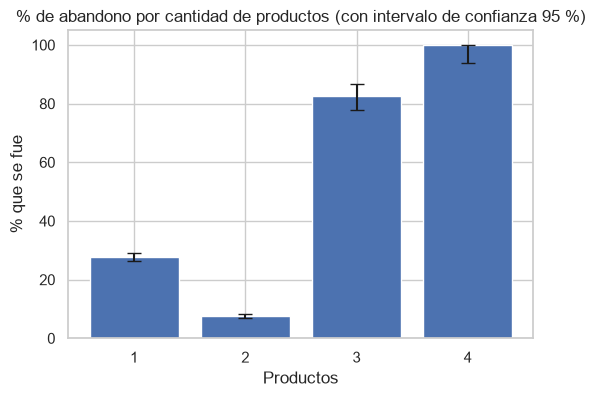

In [11]:
tabla_prod = tasa_con_ic("NumOfProducts")
print(tabla_prod)
grafico_tasas(tabla_prod, "% de abandono por cantidad de productos (con intervalo de confianza 95 %)", "Productos")

Con 2 productos el abandono es el más bajo (7,6 %). Con 1 producto es 27,7 %, y con 3 y 4 productos sube a 82,7 % y 100 %. En 3 y 4 hay pocos clientes (266 y 60), por eso sus barras de error son más largas.

### 6.2 Hipótesis
- **H0:** el abandono es **independiente** de la cantidad de productos.
- **H1:** el abandono **depende** de la cantidad de productos.

**Por qué importa al negocio:** si tener más productos ata al cliente, vender el segundo producto puede ser una forma de retenerlo. Pero la tabla sugiere que no es "más es mejor": hay que entender dónde está el punto.

**Prueba:** chi-cuadrado de independencia. Hay 4 categorías, así que revisamos con cuidado el supuesto de frecuencias esperadas, porque los grupos de 3 y 4 productos son pequeños.

### 6.3 Supuesto y prueba

In [12]:
obs = pd.crosstab(df["NumOfProducts"], df["Exited"])
chi2, p, gl, esp, v, k, res = chi_cuadrado(obs)

print("Frecuencias observadas:");  print(obs); print()
print("Esperada mínima:", round(esp.values.min(), 1), "→", "cumple el supuesto" if esp.values.min() >= 5 else "NO cumple")
print()
print(f"Chi-cuadrado = {chi2:.1f} | gl = {gl} | p = {fmt_p(p)}")
print(f"V de Cramér = {v:.2f} → efecto {tamano_v(v, k)}")
print()
print("Residuos estandarizados:"); print(res.round(1))
print()
print("Decisión (α = 0,05):", decision(p))

resultados.append({"Hipótesis": "H4 Productos", "Prueba": "Chi-cuadrado", "Estadístico": round(chi2, 1), "p": p,
                   "Decisión": decision(p), "Tamaño del efecto": f"V = {v:.2f} ({tamano_v(v, k)})"})

Frecuencias observadas:
Exited            0     1
NumOfProducts            
1              3675  1409
2              4242   348
3                46   220
4                 0    60

Esperada mínima: 12.2 → cumple el supuesto

Chi-cuadrado = 1503.6 | gl = 3 | p = menor que 1e-300 (el computador lo redondea a 0)
V de Cramér = 0.39 → efecto mediano

Residuos estandarizados:
Exited            0     1
NumOfProducts            
1              -5.9  11.6
2               9.7 -19.2
3             -11.4  22.5
4              -6.9  13.7

Decisión (α = 0,05): Se rechaza H0


### 6.4 Qué significa
- **Decisión:** el p es tan pequeño (menor que 10⁻³⁰⁰) que el computador lo redondea a 0. Se rechaza H0.
- **Dónde está la diferencia:** con 2 productos se van muchos menos clientes de los esperados (residuo −19,2). Con 1, 3 y 4 productos se van más de los esperados. No es "más productos = más lealtad": el mejor punto está en 2.
- **Qué tan fuerte:** V = 0,39, efecto mediano. Es la relación más fuerte de las cuatro.
- **Algo raro que hay que decir:** los 60 clientes con 4 productos se fueron todos, y de los 266 con 3 productos se fueron 220. Es un patrón extremo. Puede reflejar algo real del negocio o la forma en que se armó el dataset. Con estos datos no podemos saberlo, así que no basamos ninguna recomendación solo en esos dos grupos y lo dejamos como límite.

### 6.5 Una pregunta que queda abierta: ¿por qué se van los de 3 y 4 productos?
Los clientes con 3 y 4 productos se van casi todos. Antes de interpretarlo, revisamos si ese grupo se parece a otro en algo que lo explique: país, edad, actividad, antigüedad o saldo. Esto es una **exploración**, no una hipótesis nueva.

El dataset no dice qué producto es cada uno ni cuándo se contrató, así que **no podemos saber si son productos temporales**. Lo que sí podemos mirar es la antigüedad del cliente (`Tenure`), que da una pista.

**Primero: ¿cómo es el perfil de cada grupo?**

In [13]:
perfil = df.groupby("NumOfProducts").agg(
    clientes=("Exited", "size"),
    abandono_pct=("Exited", lambda s: s.mean() * 100),
    edad_prom=("Age", "mean"),
    antiguedad_prom=("Tenure", "mean"),
    saldo_prom=("Balance", "mean"),
    activos_pct=("IsActiveMember", lambda s: s.mean() * 100),
    alemania_pct=("Geography", lambda s: (s == "Germany").mean() * 100),
    mujeres_pct=("Gender", lambda s: (s == "Female").mean() * 100),
).round(1)
perfil

,clientes,abandono_pct,edad_prom,antiguedad_prom,saldo_prom,activos_pct,alemania_pct,mujeres_pct
NumOfProducts,,,,,,,,
1,5084,27.7,39.7,5.0,98551.9,50.4,26.5,45.2
2,4590,7.6,37.8,5.1,51879.1,53.3,22.7,44.9
3,266,82.7,43.2,5.0,75458.3,42.5,36.1,56.0
4,60,100.0,45.7,5.3,93733.1,48.3,40.0,63.3


**Lo que se ve:**
- El grupo de 3 y 4 productos tiene un perfil algo distinto: más mujeres (56 % y 63 %, contra 45 % en los de 1 y 2 productos), más clientes en Alemania (36 % y 40 %, contra 23 % en el grupo de 2 productos) y más edad (43 y 46 años, contra 38).
- La **antigüedad es igual en todos los grupos** (unos 5 años). No hay señal de que los de 3 y 4 productos sean clientes nuevos.
- El saldo promedio es mayor con 3 y 4 productos (75 mil y 94 mil) que con 2 (52 mil).

Son pistas, pero ninguna alcanza por sí sola para explicar que se vayan casi todos. Eso lo revisa el siguiente paso.

**Segundo: ¿el abandono de los de 3 o 4 productos se mantiene dentro de cada país, edad, actividad y antigüedad?** Si el efecto fuera solo de Alemania o de la edad, desaparecería al mirar cada grupo por separado.

In [14]:
grupos_prod = df["NumOfProducts"].map({1: "1 producto", 2: "2 productos", 3: "3 o 4 productos", 4: "3 o 4 productos"})
rangos_edad = pd.cut(df["Age"], bins=[17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", "60+"])
rangos_antig = pd.cut(df["Tenure"], bins=[-1, 2, 5, 10], labels=["0-2 años", "3-5 años", "6-10 años"])

cortes = {
    "país": df["Geography"],
    "género": df["Gender"],
    "actividad": df["IsActiveMember"].map({0: "Inactivo", 1: "Activo"}),
    "rango de edad": rangos_edad,
    "antigüedad": rangos_antig,
}

for nombre, corte in cortes.items():
    tasa = pd.crosstab(corte, grupos_prod, values=df["Exited"], aggfunc="mean").mul(100).round(1)
    n = pd.crosstab(corte, grupos_prod)
    print(f"--- Abandono (%) según productos, dentro de cada {nombre} ---")
    print(tasa)
    print("Clientes:")
    print(n)
    print()

--- Abandono (%) según productos, dentro de cada país ---
NumOfProducts  1 producto  2 productos  3 o 4 productos
Geography                                              
France               22.4          5.7             83.5
Germany              42.8         12.1             91.7
Spain                21.9          7.4             80.8
Clientes:
NumOfProducts  1 producto  2 productos  3 o 4 productos
Geography                                              
France               2514         2367              133
Germany              1349         1040              120
Spain                1221         1183               73

--- Abandono (%) según productos, dentro de cada género ---
NumOfProducts  1 producto  2 productos  3 o 4 productos
Gender                                                 
Female               33.2         10.2             89.3
Male                 23.2          5.5             81.3
Clientes:
NumOfProducts  1 producto  2 productos  3 o 4 productos
Gender               

**Lo que se ve:** el abandono de los de 3 o 4 productos es altísimo **en todos los grupos**:
- **País:** 83,5 % en Francia, 80,8 % en España y 91,7 % en Alemania. Alemania es peor, pero Francia y España también son muy altos.
- **Género:** 89,3 % en mujeres y 81,3 % en hombres.
- **Actividad:** 80,3 % en activos y 90,2 % en inactivos.
- **Edad:** desde 63,6 % entre 18 y 30 años hasta 98,3 % entre 51 y 60.
- **Antigüedad:** entre 84,5 % y 87,5 %, sin importar los años como cliente.

Con 2 productos, en cambio, el abandono es bajo en todos esos grupos (entre 2,7 % y 29,5 %). Es decir, **no es un efecto de Alemania, de la edad, del género, de la actividad ni de la antigüedad**: el patrón aparece igual en todos.

Dos cosas más que aparecen aquí:
- **La edad no sube en línea recta.** El abandono es mayor entre los 41 y los 60 años y baja a partir de los 60. Con 1 producto, por ejemplo: 44,0 % a los 41-50, 63,8 % a los 51-60 y 30,1 % a los 60+. La diferencia de promedios de la H1 esconde este pico; en la Fase 3 usaremos rangos de edad.
- **La antigüedad no cambia el abandono.** Cada columna es casi igual entre 0-2, 3-5 y 6-10 años. Ya sabemos que el abandono no depende de cuántos años lleva el cliente.

**Tercero: ¿sigue pesando la cantidad de productos si se controlan las otras variables a la vez?** Usamos una regresión logística, que estima la probabilidad de irse considerando todas las variables juntas. Se lee con la **razón de momios (odds ratio)**: mayor que 1 significa más probabilidad de irse, menor que 1 significa menos, **manteniendo lo demás igual**. Las categorías de referencia son 2 productos, Francia y hombre.

In [15]:
from sklearn.linear_model import LogisticRegression

X = pd.get_dummies(pd.DataFrame({
    "productos": grupos_prod,
    "pais": df["Geography"],
    "genero": df["Gender"],
    "activo": df["IsActiveMember"],
    "edad_cada_10_anios": df["Age"] / 10,
    "antiguedad_anios": df["Tenure"],
    "saldo_cada_100mil": df["Balance"] / 100000,
}), columns=["productos", "pais", "genero"])
X = X.drop(columns=["productos_2 productos", "pais_France", "genero_Male"]).astype(float)

modelo = LogisticRegression(C=1e6, max_iter=2000).fit(X, df["Exited"])
razones = pd.Series(np.exp(modelo.coef_[0]), index=X.columns).round(2).sort_values(ascending=False)
print("Razón de momios (más de 1 = más probabilidad de irse):")
print(razones.to_string())

Razón de momios (más de 1 = más probabilidad de irse):
productos_3 o 4 productos    77.13
productos_1 producto          4.69
pais_Germany                  2.56
edad_cada_10_anios            2.04
genero_Female                 1.69
pais_Spain                    1.05
antiguedad_anios              0.98
saldo_cada_100mil             0.94
activo                        0.33


**Cómo leerlo:** cada número dice cuánto cambia la probabilidad de irse **si lo demás se mantiene igual**.
- **3 o 4 productos: 77** (frente a 2 productos). Aun controlando país, edad, género, actividad, antigüedad y saldo, es de lejos el factor más fuerte. El número es enorme porque el grupo es extremo (casi todos se van) y pequeño (326 clientes): sirve para ordenar qué pesa más, no como cifra exacta.
- **1 producto: 4,7.** También se va más que con 2 productos.
- **Alemania: 2,6** frente a Francia. **España: 1,05**, casi igual a Francia.
- **Edad: 2,0 por cada 10 años más.** Ojo: este modelo supone que la edad sube en línea recta y vimos que no es así.
- **Mujer: 1,7** frente a hombre.
- **Cliente activo: 0,33.** Ser activo baja mucho la probabilidad de irse.
- **Antigüedad (0,98) y saldo (0,94):** casi no cambian nada una vez que se controla lo demás.

### Conclusión de esta exploración
- La relación entre 3 o 4 productos y el abandono **no se explica por** país, edad, género, actividad ni antigüedad: se mantiene dentro de cada grupo y también en el modelo.
- Algo del propio producto o de cómo se contrató queda fuera de estos datos (cuáles son esos productos, si tienen condiciones especiales, si cerrar el último implica cerrar la cuenta). No lo sabemos y no afirmamos ninguna causa.
- **Decisión para el proyecto:** lo tratamos como un hallazgo fuerte y como una **alerta**. En el dashboard vigilamos el indicador de clientes con 3 o más productos, y en la Fase 6 recomendamos que el banco revise esos productos con sus datos internos.

## 7. Resumen de las cuatro hipótesis
Como hacemos cuatro pruebas a la vez, aumenta la probabilidad de que alguna salga significativa por pura casualidad. Para cubrirnos, repetimos la decisión con la **corrección de Bonferroni**: dividimos α entre el número de pruebas (0,05 / 4 = 0,0125).

In [16]:
resumen = pd.DataFrame(resultados)
resumen["Decisión con Bonferroni (α = 0,0125)"] = [decision(x, ALFA / len(resultados)) for x in resumen["p"]]
resumen["p"] = resumen["p"].map(lambda x: "< 1e-300" if x == 0 else f"{x:.2e}")
resumen

,Hipótesis,Prueba,Estadístico,p,Decisión,Tamaño del efecto,"Decisión con Bonferroni (α = 0,0125)"
0,H1 Edad,t de Welch,30.42,4.71e-179,Se rechaza H0,d = 0.74 (mediano),Se rechaza H0
1,H2 País,Chi-cuadrado,301.30,3.83e-66,Se rechaza H0,V = 0.17 (pequeño),Se rechaza H0
2,H3 Actividad,Chi-cuadrado,243.00,8.79e-55,Se rechaza H0,V = 0.16 (pequeño),Se rechaza H0
3,H4 Productos,Chi-cuadrado,1503.60,< 1e-300,Se rechaza H0,V = 0.39 (mediano),Se rechaza H0


**Lectura del resumen:** las cuatro hipótesis se rechazan, también con la corrección de Bonferroni. Lo que cambia es la fuerza (cada medida tiene su propia escala):
- Efecto **mediano:** cantidad de productos (V = 0,39) y edad (d = 0,74).
- Efecto **pequeño:** país (V = 0,17) y actividad (V = 0,16).

Si el banco tiene poco presupuesto, productos y edad son los primeros lugares donde mirar.

## 8. Lectura crítica
- **Significativo no es lo mismo que importante.** Con 10.000 clientes, hasta diferencias pequeñas dan p muy bajo. Por eso miramos el tamaño del efecto y los intervalos de confianza.
- **Relación no es causa.** Que los clientes inactivos se vayan más no prueba que la inactividad los haga irse. Puede haber otras razones que no están en los datos.
- **Rechazar H0 no prueba H1.** Solo dice que los datos son poco compatibles con H0.
- **Grupos pequeños y patrón extremo.** Hay 266 clientes con 3 productos y 60 con 4, y casi todos se fueron. Cualquier conclusión sobre ellos es frágil.
- **Una muestra de un banco.** Los resultados valen para clientes parecidos a estos, no para cualquier banco.
- **Las variables pueden estar mezcladas.** Alemania, por ejemplo, tiene más clientes con 3 o 4 productos. Estas pruebas miran una variable a la vez. En la sección 6.5 lo comprobamos para los productos: el efecto se mantiene dentro de cada país, edad, género y actividad. El modelo de riesgo de la Fase 4 considera todas las variables juntas.
- **La edad no sube en línea recta.** El abandono alcanza su punto más alto entre los 41 y los 60 años y baja después. Comparar solo promedios (H1) esconde ese pico, por eso en el dashboard usamos rangos de edad.
- **Hay algo que no vemos en los productos.** Los clientes con 3 o 4 productos se van casi todos sin importar el perfil. No sabemos qué productos son; queda como alerta para el banco.

## 9. Conexión con los KPIs (Fase 4)
Cada hipótesis alimenta un indicador del dashboard:

| Hipótesis | KPI que alimenta |
|---|---|
| H1 Edad | Edad promedio de los clientes que se van, y abandono por rango de edad |
| H2 País | Tasa de abandono por país |
| H3 Actividad | Tasa de abandono de clientes inactivos |
| H4 Productos | Distribución de clientes y abandono por cantidad de productos |
| Todas | Tasa de abandono global y saldo en riesgo |

## 10. Cierre de la Fase 2
| Requisito | Dónde |
|---|---|
| Al menos 2 hipótesis con H0 y H1 | Secciones 3 a 6 (cuatro hipótesis) |
| Justificación ligada al negocio | Cada sección, apartado de hipótesis |
| Variables del dataset | Edad, país, actividad y productos frente a `Exited` |
| Prueba pertinente | t de Welch para medias; chi-cuadrado para categóricas |
| Supuestos revisados | Q-Q, Levene, frecuencias esperadas |
| p-valor y decisión con α = 0,05 | Cada prueba, más Bonferroni en la sección 7 |
| Tamaño del efecto e intervalos de confianza | Cada prueba |
| Errores tipo I y II | Sección 1 |
| Limitaciones | Sección 8 |